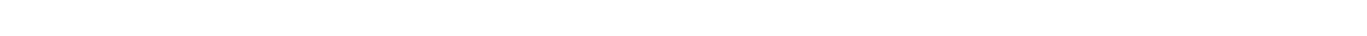

In [ ]:
import marimo as mo

# NB 2.02: Baseline b2, untuned Llama-3.2-1B-Instruct, one question per request (dataset v2)

| | |
|---|---|
| **Experiment(s)** | `b2`: untuned baseline of the student model (RESEARCH_LOG decision 2026-11-11: student = Llama-3.2-1B) in the app's per-part format (Entries 8–9) |
| **Paper / report** | Results Summary §6.1, b2 rows (per-part and whole-exercise) |
| **Env** | Marimo machine with a GPU (RTX 6000 class); the kernel's torch + transformers (installed only if absent), `xgrammar` for the app's JSON rule |
| **Inputs** | HF dataset `emmilly/vnest-exercise-llm-outputs`: `data/v2/{train,validation,test}.jsonl` + `data/v2/SHA256SUMS` (checksums verified). Model `meta-llama/Llama-3.2-1B-Instruct` (**gated**: the HF account must have accepted Meta's Llama 3.2 licence) |
| **Outputs** | Same HF repo: `runs/b2-llama32-1b-instruct-untuned/` (config, raw generations, resources, `_done/` markers); `preds/b2__2.02__<run>__<split>__forced-<dec>.csv` (one row per question), `…__chain-<dec>.csv` (one row per exercise), `…__chain-<dec>-attempts.csv` (every try); `tables/b2__2.02__{forced-summary,forced-by-part,chain-summary,per-verb}.csv`. W&B `team-me-and-me/vnest-exercise-llm`, run id = run name |
| **What it measures** | Two protocols × 2 decodings on validation (41 exercises) and test (76 exercises, 5 verbs). **forced**: each question alone, given the reference earlier answers (as in the training data), greedy. **chain**: whole exercises as the app writes them: the model's own earlier answers, ≤ 3 tries per question, stop at a question that never passes, what ≠ who; sampled at temperature 0.3 like the app (greedy would make retries identical), fixed seed. Decodings: `schema` = the app's JSON rule (`wc.PART_SCHEMA`, xgrammar), `free` = none. Scores: `vnest_common` 1.1.1 (`score_part`, `score_chain`), **automatic only**, no therapist judgement |
| **Decoding** | Max 48 new tokens per question (the app's limit), explicit stop tokens (`wc.stop_token_ids`: generation config + `<\|eot_id\|>`), bf16 on GPU (not the phone's 4-bit model) |
| **Keys** | KEYS cell below (HF token of `emmilly` with write access and Llama 3.2 access, W&B API key), or env vars `HF_TOKEN` / `WANDB_API_KEY` |
| **How to run** | Interactive: open in Marimo, run all. Unattended: `mkdir -p ~/vnest/logs && nohup python 02_baseline_llama32_1b_untuned_parts.py > ~/vnest/logs/2.02_baseline_llama1b.log 2>&1 &` then `tail -f ~/vnest/logs/2.02_baseline_llama1b.log` |
| **Memory / batch** | ~3 GB GPU for the model; `BATCH_SIZE` 32 halves itself on out-of-memory |
| **Resume after a crash** | Each of the 8 parts (split × protocol × decoding) is uploaded as soon as it finishes; a re-run reads finished parts back from HF and only generates the rest. Scoring re-runs automatically if the raw outputs changed (fingerprint) |
| **Runtime** | Roughly 5–15 min on an RTX 6000 (≈ 1,200 forced questions + up to ≈ 3,500 chained tries) |
| **Smoke test (offline)** | `VNEST_OFFLINE=1 VNEST_OFFLINE_DIR=<folder with data/v2/> VNEST_LIMIT=4 [VNEST_SMOKE_MODEL=<local model dir>] python 02_….py`: nothing is uploaded, run name gets `-smoke` |
| **Forked from** | NB 2.01 (`01_baseline_qwen25_untuned.py`, b1). Changed: model (Llama-3.2-1B), dataset v2 and the per-part format (prompts `wc.part_prompt`, system `wc.PART_SYSTEM_PROMPT`, JSON rule `wc.PART_SCHEMA`, 48 tokens), the chained protocol, explicit stop tokens and a cut-off flag per output (from `notes/nb2.02_stop_token_fix.patch`), offline smoke mode, module 1.1.1 |

**Test = 5 verbs (cook, drive, paint, plant, wash), 76 exercises (380 questions).** Validation = chop, eat, lift, play, smell (41 exercises). Every number is over 5 verbs; confidence intervals resample verbs. b1 (NB 2.01) used dataset v1 and whole-exercise prompts, so b1 and b2 are **not** directly comparable.

In [ ]:
# ══════════════ KEYS: paste yours between the quotes (only if not already set as environment variables) ══════════════
HF_TOKEN = "hf_YOUR_TOKEN_HERE"          # ← HF token of account emmilly, WRITE access + Llama 3.2 access (huggingface.co/settings/tokens)
WANDB_API_KEY = "wandb_YOUR_KEY_HERE"    # ← W&B API key (wandb.ai/authorize)
# ════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
# Exported .ipynb files keep whatever is pasted above: put the placeholders back before sharing a file.
if "YOUR_TOKEN" in HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")
if "YOUR_KEY" in WANDB_API_KEY:
    WANDB_API_KEY = os.environ.get("WANDB_API_KEY", "")
os.environ["HF_TOKEN"] = HF_TOKEN
if WANDB_API_KEY:
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
print(f"HF_TOKEN set: {bool(HF_TOKEN)} | WANDB_API_KEY set: {bool(WANDB_API_KEY)}")

HF_TOKEN set: True | WANDB_API_KEY set: True


In [ ]:
import gc
import hashlib
import json
import os
import sys
import time
from pathlib import Path

In [ ]:
# ───────────────────────────── config: everything tunable lives here ─────────────────────────────
NOTEBOOK = "2.02"
EXP_ID = "b2"
MODEL_ID = os.environ.get("VNEST_SMOKE_MODEL") or "meta-llama/Llama-3.2-1B-Instruct"
MODEL_SHORT = "llama32-1b-instruct"
SMOKE = bool(os.environ.get("VNEST_SMOKE_MODEL") or os.environ.get("VNEST_LIMIT") or os.environ.get("VNEST_OFFLINE"))
VARIANT = "untuned-smoke" if SMOKE else "untuned"
RUN_NAME = f"{EXP_ID}-{MODEL_SHORT}-{VARIANT}"   # checked by wc.run_name below

SPLITS = ["validation", "test"]          # never select anything on test
PROTOCOLS = ["forced", "chain"]          # forced = reference earlier answers (as in training); chain = the app's way
DECODINGS = ["schema", "free"]           # schema = the app's JSON rule (xgrammar); free = none
MAX_NEW_TOKENS = 48                      # the app's limit per question (checked against wc.PART_MAX_NEW_TOKENS)
CHAIN_TEMPERATURE = 0.3                  # the app samples at 0.3; retries need sampling to differ
CHAIN_SEED = 20261111                    # fixed: chained runs are reproducible for the same batching
BATCH_SIZE = 32                          # halves automatically on GPU out-of-memory
TORCH_DTYPE = "bfloat16"
LIMIT_PER_SPLIT = int(os.environ["VNEST_LIMIT"]) if os.environ.get("VNEST_LIMIT") else None  # exercises per split

STAGES = {"generate": True, "score": True, "summary": True}
FORCE = set()                            # e.g. {"score"} to redo a finished stage

WORK_ROOT = Path(os.environ.get("VNEST_WORK", str(Path.home() / "vnest")))
WORK_DIR = WORK_ROOT / "runs" / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=True)
CFG = dict(notebook=NOTEBOOK, exp_id=EXP_ID, model_id=MODEL_ID, variant=VARIANT, run_name=RUN_NAME,
           splits=SPLITS, protocols=PROTOCOLS, decodings=DECODINGS, max_new_tokens=MAX_NEW_TOKENS,
           forced_decoding="greedy", chain_temperature=CHAIN_TEMPERATURE, chain_seed=CHAIN_SEED,
           batch_size=BATCH_SIZE, torch_dtype=TORCH_DTYPE, limit_per_split=LIMIT_PER_SPLIT, smoke=SMOKE,
           schema_grammar="xgrammar json_schema(PART_SCHEMA), any_whitespace=False, separators=(', ', ': ')")
print(f"run {RUN_NAME} | model {MODEL_ID} | work dir {WORK_DIR}" + (" | SMOKE TEST" if SMOKE else ""))

run b2-llama32-1b-instruct-untuned | model meta-llama/Llama-3.2-1B-Instruct | work dir /home/marimo/vnest/runs/b2-llama32-1b-instruct-untuned


In [ ]:
# ───────────── shared module (vnest_common), embedded; regenerate with tools/make_standalone.py ─────────────
import base64 as _b64
import importlib as _il
import subprocess as _sp
_EMBED_VERSION = "1.1.1"
_EMBED_B64 = "..."  # >>> vnest_common (do not edit: tools/make_standalone.py)
for _pkg in ("huggingface_hub", "pandas", "numpy"):
    try:
        _il.import_module(_pkg)
    except ImportError:
        _sp.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)
_dir = Path(WORK_ROOT) / "common"
_dir.mkdir(parents=True, exist_ok=True)
(_dir / "vnest_common.py").write_bytes(_b64.b64decode(_EMBED_B64))
if str(_dir) not in sys.path:
    sys.path.insert(0, str(_dir))
import vnest_common as wc
wc = _il.reload(wc)
assert wc.VERSION == _EMBED_VERSION, (wc.VERSION, _EMBED_VERSION)
_acct = wc.whoami()
print(f"vnest_common {wc.VERSION} | HF token account: {_acct}" + (" | OFFLINE (no uploads)" if wc.offline() else ""))
if _acct != wc.HF_USER:
    print(f"WARNING: token belongs to {_acct!r}, not {wc.HF_USER!r}: uploads to {wc.OUTPUTS_REPO} will fail (403)")

vnest_common 1.1.1 | HF token account: emmilly


In [ ]:
# ───────────── libraries (env vars before CUDA initialises; install only if absent, never upgrade) ─────────────
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import importlib as _il2
import subprocess as _sp2
for _pkg, _mod in (("transformers", "transformers"), ("accelerate", "accelerate"), ("xgrammar", "xgrammar"),
                   ("wandb", "wandb")):
    try:
        _il2.import_module(_mod)
    except ImportError:
        print(f"installing {_pkg}")
        _r = _sp2.run([sys.executable, "-m", "pip", "install", "-q", _pkg])
        if _r.returncode != 0:
            print(f"could not install {_pkg} (rc {_r.returncode})")
import pandas as pd
import torch
import transformers
try:
    import xgrammar as xgr
    import xgrammar.contrib.hf  # noqa: F401  (the transformers logits processor)
    XGR_ERROR = None
except Exception as _e:
    xgr, XGR_ERROR = None, f"{type(_e).__name__}: {_e}"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
import importlib.metadata as _md
VERSIONS = {"python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
            "xgrammar": _md.version("xgrammar") if xgr else None, "pandas": pd.__version__,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"}
print(VERSIONS)
if XGR_ERROR:
    print(f"WARNING: xgrammar unavailable ({XGR_ERROR}): the 'schema' parts will be skipped and reported as such")
if DEVICE != "cuda":
    print("WARNING: no GPU found: generation will be slow")

installing accelerate



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


installing xgrammar



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


{'python': '3.13.11', 'torch': '2.11.0+cu130', 'transformers': '5.14.1', 'xgrammar': '0.2.9', 'pandas': '3.0.3', 'gpu': 'NVIDIA RTX PRO 6000 Blackwell Server Edition'}


In [ ]:
# ───────────── data: download data/v2, verify checksums, enforce the split rule, build items ─────────────
assert wc.DATA_VERSION == "v2" and MAX_NEW_TOKENS == wc.PART_MAX_NEW_TOKENS, (wc.DATA_VERSION, MAX_NEW_TOKENS)
with mo.status.spinner(title=f"Downloading dataset {wc.DATA_VERSION}"):
    _sums_p = wc.hf_download(f"data/{wc.DATA_VERSION}/SHA256SUMS", WORK_DIR)
    assert _sums_p, f"data/{wc.DATA_VERSION}/SHA256SUMS missing in {wc.OUTPUTS_REPO}"
    EXPECTED_SHA = dict(reversed(_l.split()) for _l in _sums_p.read_text().splitlines() if _l.strip())
    _rows, DATA_SHA = {}, {}
    for _split in ("train", "validation", "test"):
        _p = wc.hf_download(wc.data_path(_split), WORK_DIR)
        assert _p, f"{wc.data_path(_split)} missing"
        DATA_SHA[_split] = wc.sha256_file(_p)
        assert DATA_SHA[_split] == EXPECTED_SHA[f"{_split}.jsonl"], f"{_split}.jsonl checksum mismatch"
        _rows[_split] = wc.load_jsonl(_p)
_ov = wc.check_split_verbs(_rows["train"], _rows["validation"], _rows["test"])
print(f"verb overlap train&val={_ov['train&val']} train&test={_ov['train&test']} val&test={_ov['val&test']} (must all be [])")
assert not (_ov["train&val"] or _ov["train&test"] or _ov["val&test"]), "split rule broken"
assert tuple(_ov["test_verbs"]) == wc.TEST_VERBS, _ov["test_verbs"]
assert all(r["messages"][0]["content"] == wc.PART_SYSTEM_PROMPT for r in _rows["test"]), "system line differs from the app's"

ITEMS_FORCED, ITEMS_CHAIN = {}, {}
for _split in SPLITS:
    _chain = wc.chain_items_from_split(_rows[_split], _split)
    _forced = wc.part_items_from_split(_rows[_split], _split)
    if LIMIT_PER_SPLIT:  # deterministic, nested subset of exercises; forced items follow the kept exercises
        _keep = set(wc.subset_md5([c["exercise_id"] for c in _chain], LIMIT_PER_SPLIT, salt=_split))
        _chain = [c for c in _chain if c["exercise_id"] in _keep]
        _forced = [f for f in _forced if f"{_split}:{f['sentence_id']}#{f['variant']}" in _keep]
    for _f in _forced:  # the dataset prompt, rebuilt exactly (checked offline in test_vnest_common.py too)
        assert wc.part_prompt(_f["verb"], _f["part"], _f["done"], _f["avoid"]) == _rows[_split][_f["idx"]]["messages"][1]["content"]
    ITEMS_CHAIN[_split], ITEMS_FORCED[_split] = _chain, _forced
REFS = wc.known_valid([i for _s in ("validation", "test") for i in wc.part_items_from_split(_rows[_s], _s)])
print("checksums OK |", {k: len(v) for k, v in ITEMS_CHAIN.items()}, "exercises |",
      {k: len(v) for k, v in ITEMS_FORCED.items()}, "questions | DATA_SHA", {k: v[:10] for k, v in DATA_SHA.items()})

verb overlap train&val=[] train&test=[] val&test=[] (must all be [])
checksums OK | {'validation': 41, 'test': 76} exercises | {'validation': 205, 'test': 380} questions | DATA_SHA {'train': 'd0893825ec', 'validation': '6c85f23160', 'test': 'f640592b5c'}


In [ ]:
# ───────────── bookkeeping: run lock, stages, W&B, config on HF ─────────────
_parts = wc.parse_run_name(RUN_NAME)
assert wc.run_name(_parts["exp"], _parts["model"], _parts["variant"]) == RUN_NAME and _parts["exp"] == EXP_ID, RUN_NAME
LOCK = wc.claim_run(WORK_DIR)
wc.ensure_outputs_repo(HF_TOKEN)
stages = wc.Stages(RUN_NAME, STAGES, FORCE, WORK_DIR, HF_TOKEN)
RUN_CONFIG = {**CFG, "data_version": wc.DATA_VERSION, "data_sha256": DATA_SHA, "module_version": wc.VERSION,
              "versions": VERSIONS, "git_commit": "unknown", "system_prompt": wc.PART_SYSTEM_PROMPT,
              "scoring": "vnest_common.score_part / score_chain (automatic only)"}
wb, log_fn = (None, None) if wc.offline() else wc.wandb_init(
    RUN_NAME, "eval", [f"exp:{EXP_ID}", f"nb:{NOTEBOOK}", "model:llama-3.2-1b-instruct", "variant:untuned", "baseline",
                       "format:per-part", f"data:{wc.DATA_VERSION}"], RUN_CONFIG)
wc.put_json(RUN_CONFIG, f"{wc.run_dir(RUN_NAME)}/config.json", WORK_DIR, f"{RUN_NAME}: config", HF_TOKEN)
RESOURCES_CSV = WORK_DIR / "resources.csv"
print(f"lock {LOCK} | W&B {'on' if wb else 'off'} | config saved")

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: enamugan (team-me-and-me) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run b2-llama32-1b-instruct-untuned
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /marimo/wandb/run-20261111_075303-b2-llama32-1b-instruct-untuned
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run b2-llama32-1b-instruct-untuned
wandb: ⭐️ View project at https://wandb.ai/team-me-and-me/vnest-exercise-llm
wandb: 🚀 View run at https://wandb.ai/team-me-and-me/vnest-exercise-llm/runs/b2-llama32-1b-instruct-untuned


lock /home/marimo/vnest/runs/b2-llama32-1b-instruct-untuned/run.lock | W&B on | config saved


[hf] download runs/b2-llama32-1b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af41ee1-77f4c5ce26b7adb4626f00a0;58dff2f4-5ccb-4292-849f-630271f1fe5c)

Entry Not -> retry in 5s
[hf] download runs/b2-llama32-1b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af41ee6-610ed39c4d4b7d7d699976a0;ba99376b-574f-4011-82f1-4713547410cf)

Entry Not -> retry in 10s
[hf] download runs/b2-llama32-1b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af41ef0-4d3ce86561e545e7220abafe;6a283750-6d56-41c0-8586-4c72f9109ec7)

Entry Not -> retry in 20s
[hf] download runs/b2-llama32-1b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af41f04-2829ab842293ae843816b234;818c181f-1f7e-416d-84f6-da9e976b4348)

Entry Not -> retry in 40s
[hf] download runs/b2-llama32-1b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af41f2c-2bb00fac1bc4e72b2d60c544;4287d604-8ad1-4daa-bc22-2a

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2498.21it/s]


model loaded | stop tokens [128001, 128008, 128009] = ['<|end_of_text|>', '<|eom_id|>', '<|eot_id|>']


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[resources] generate-validation-forced-schema: ok | 0.0019 h | peak GPU 2.98 GB | 1135.4 tok/s
[generate] validation/forced-schema: 205 outputs, 0 empty, 129 distinct, mean 38 tokens, 28 cut off at 48
[resources] generate-validation-forced-free: ok | 0.0012 h | peak GPU 2.98 GB | 1720.1 tok/s
[generate] validation/forced-free: 205 outputs, 0 empty, 130 distinct, mean 38 tokens, 28 cut off at 48
[resources] generate-validation-chain-schema: ok | 0.0022 h | peak GPU 2.97 GB | 945.4 tok/s
[generate] validation/chain-schema: 208 outputs, 0 empty, 171 distinct, mean 35 tokens, 1 cut off at 48, passed 34% of tries
[resources] generate-validation-chain-free: ok | 0.0018 h | peak GPU 2.97 GB | 1136.9 tok/s
[generate] validation/chain-free: 210 outputs, 0 empty, 176 distinct, mean 35 tokens, 2 cut off at 48, passed 31% of tries
[resources] generate-test-forced-schema: ok | 0.0023 h | peak GPU 2.98 GB | 1636.0 tok/s
[generate] test/forced-schema: 380 outputs, 0 empty, 195 distinct, mean 36 token

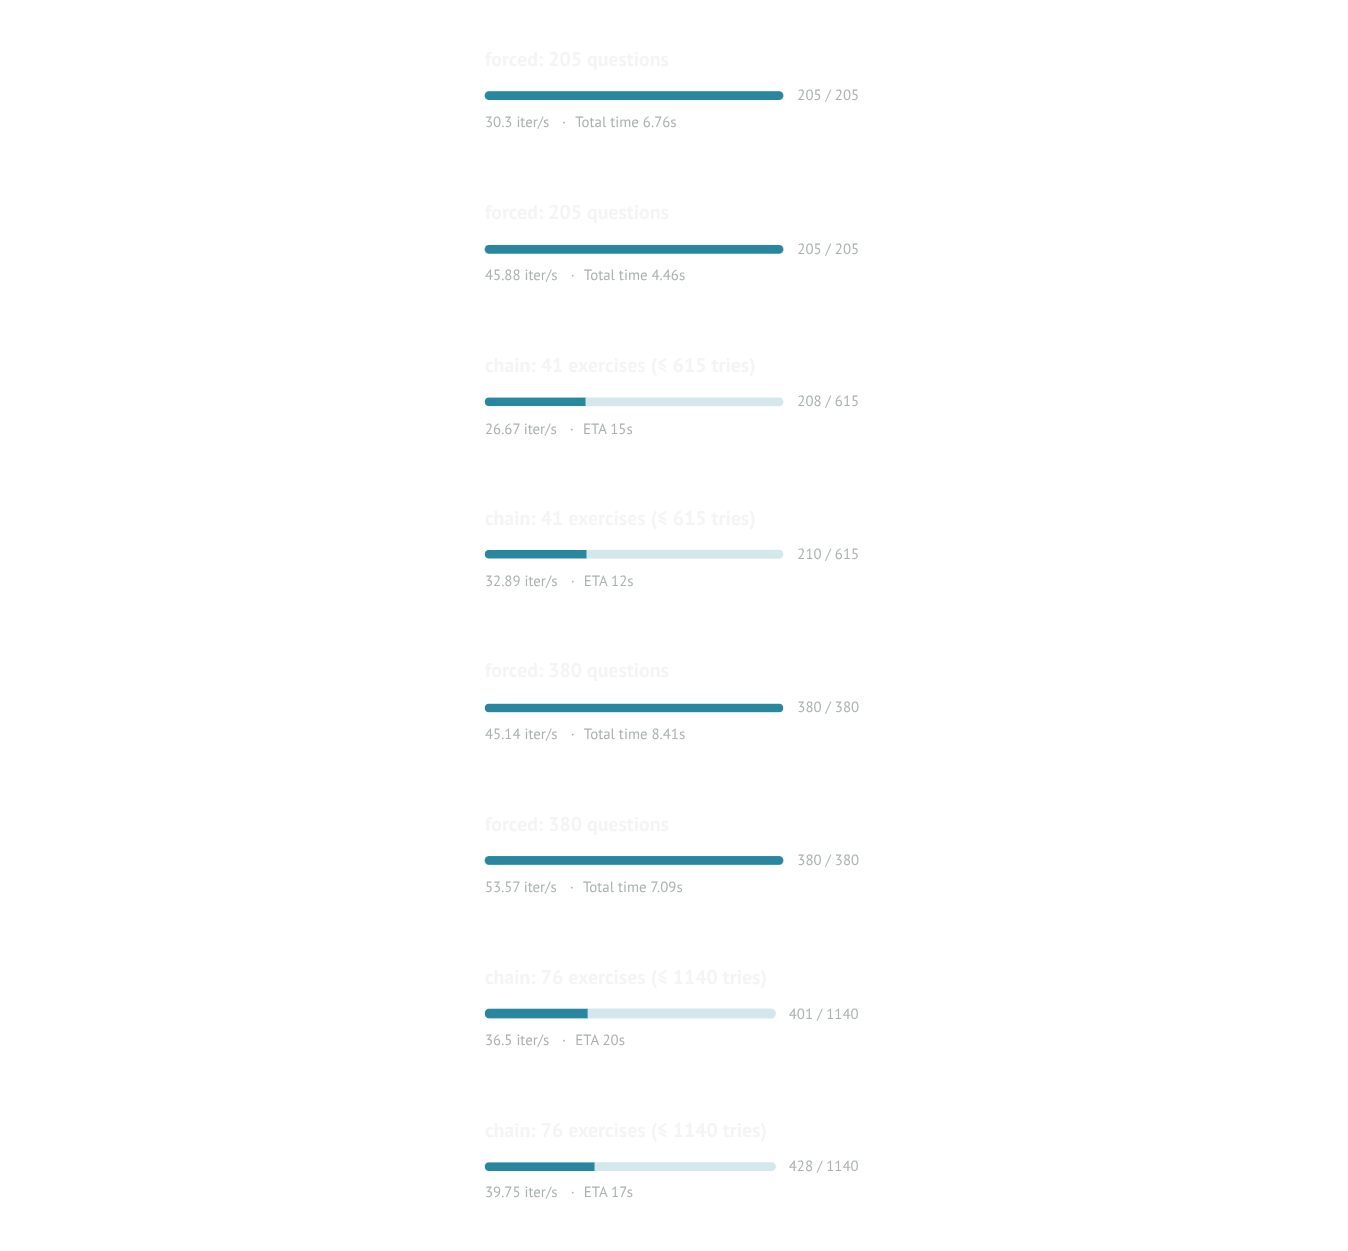

In [ ]:
# ───────────── stage: generate (8 parts = split × protocol × decoding, each saved to HF as soon as it finishes) ─────────────
PARTS = [(s, p, d) for s in SPLITS for p in PROTOCOLS for d in DECODINGS]

def _raw_path(split_, proto_, dec_):
    return f"{wc.run_dir(RUN_NAME)}/raw/{split_}__{proto_}-{dec_}.csv"

def _load_model():
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok_ = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN or None)
    tok_.padding_side = "left"  # decoder-only batching
    if tok_.pad_token is None:
        tok_.pad_token = tok_.eos_token
    try:
        model_ = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=getattr(torch, TORCH_DTYPE), token=HF_TOKEN or None)
    except TypeError:  # transformers < 4.56 calls it torch_dtype
        model_ = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=getattr(torch, TORCH_DTYPE), token=HF_TOKEN or None)
    model_.to(DEVICE).eval()
    stops_ = wc.stop_token_ids(tok_, model_.generation_config.eos_token_id)
    print(f"model loaded | stop tokens {stops_} = {[tok_.convert_ids_to_tokens(i_) for i_ in stops_]}")
    return tok_, model_, stops_

def _grammar(tok_, model_):
    info_ = xgr.TokenizerInfo.from_huggingface(tok_, vocab_size=model_.config.vocab_size)
    # Compact JSON with the dataset's separators (json.dumps); any whitespace would let a model fill 48 tokens with spaces.
    return xgr.GrammarCompiler(info_).compile_json_schema(json.dumps(wc.PART_SCHEMA), any_whitespace=False,
                                                          separators=(", ", ": "))

def _generate(tok_, model_, stops_, prompts_, compiled_, sample_, seed_):
    """[(text, n_tokens, hit_token_limit)] for user prompts; system = the app's per-part system line."""
    msgs_ = [[{"role": "system", "content": wc.PART_SYSTEM_PROMPT}, {"role": "user", "content": p_}] for p_ in prompts_]
    texts_ = [tok_.apply_chat_template(m_, tokenize=False, add_generation_prompt=True) for m_ in msgs_]
    enc_ = tok_(texts_, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
    kw_ = dict(max_new_tokens=MAX_NEW_TOKENS, pad_token_id=tok_.pad_token_id, eos_token_id=stops_)
    if sample_:
        torch.manual_seed(seed_)
        kw_.update(do_sample=True, temperature=CHAIN_TEMPERATURE, top_p=1.0, top_k=0)
    else:
        kw_.update(do_sample=False, temperature=None, top_p=None, top_k=None)
    if compiled_ is not None:
        from transformers import LogitsProcessorList
        kw_["logits_processor"] = LogitsProcessorList([xgr.contrib.hf.LogitsProcessor(compiled_)])
    with torch.no_grad():
        out_ = model_.generate(**enc_, **kw_)
    res_ = []
    for row_ in out_[:, enc_["input_ids"].shape[1]:]:
        ids_ = []
        for t_ in row_.tolist():  # tokens up to and including the first stop token
            ids_.append(t_)
            if t_ in stops_:
                break
        cut_ = not ids_ or ids_[-1] not in stops_
        res_.append((tok_.decode(ids_, skip_special_tokens=True), len(ids_), cut_))
    return res_

def _batched(tok_, model_, stops_, prompts_, compiled_, sample_, seed_, bar_):
    """_generate over all prompts in batches; halves the batch on out-of-memory."""
    res_, bs_, i_ = [], BATCH_SIZE, 0
    while i_ < len(prompts_):
        chunk_ = prompts_[i_:i_ + bs_]
        try:
            res_.extend(_generate(tok_, model_, stops_, chunk_, compiled_, sample_, seed_ + i_))
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            if bs_ == 1:
                raise
            bs_ = max(1, bs_ // 2)
            print(f"  out of memory: batch size -> {bs_}")
            continue
        bar_.update(increment=len(chunk_))
        i_ += len(chunk_)
    return res_

def _run_forced(tok_, model_, stops_, compiled_, items_):
    prompts_ = [wc.part_prompt(it_["verb"], it_["part"], it_["done"], it_["avoid"]) for it_ in items_]
    t0_ = time.time()
    with mo.status.progress_bar(total=len(items_), title=f"forced: {len(items_)} questions", show_eta=True, show_rate=True) as b_:
        outs_ = _batched(tok_, model_, stops_, prompts_, compiled_, False, 0, b_)
    dt_ = (time.time() - t0_) / max(1, len(items_))
    return pd.DataFrame([{"split": it_["split"], "idx": it_["idx"], "verb": it_["verb"], "part": it_["part"],
                          "sentence_id": it_["sentence_id"], "variant": it_["variant"], "ref_answer": it_["ref_answer"],
                          "prompt": p_, "output": t_, "gen_tokens": n_, "hit_token_limit": c_,
                          "sec_per_item_batched": round(dt_, 3)}
                         for it_, p_, (t_, n_, c_) in zip(items_, prompts_, outs_)])

def _run_chain(tok_, model_, stops_, compiled_, items_):
    """The app's procedure (LlmService.generateScenario), batched across exercises: for each part in order, up to
    wc.PART_TRIES tries; a part passes wc.part_accept (+ what != who); an exercise stops at a part that never passes."""
    state_ = {it_["exercise_id"]: {"done": {}, "alive": True} for it_ in items_}
    rows_, total_ = [], len(items_) * len(wc.QUESTIONS) * wc.PART_TRIES
    with mo.status.progress_bar(total=total_, title=f"chain: {len(items_)} exercises (≤ {total_} tries)", show_eta=True, show_rate=True) as b_:
        for pi_, part_ in enumerate(wc.QUESTIONS):
            for try_ in range(1, wc.PART_TRIES + 1):
                pend_ = [it_ for it_ in items_ if state_[it_["exercise_id"]]["alive"] and part_ not in state_[it_["exercise_id"]]["done"]]
                if not pend_:
                    break
                prompts_ = [wc.part_prompt(it_["verb"], part_, state_[it_["exercise_id"]]["done"],
                                           it_["avoid"] if part_ == "who" else None) for it_ in pend_]
                outs_ = _batched(tok_, model_, stops_, prompts_, compiled_, True, CHAIN_SEED + 1000 * pi_ + 100 * try_, b_)
                for it_, p_, (t_, n_, c_) in zip(pend_, prompts_, outs_):
                    st_ = state_[it_["exercise_id"]]
                    obj_, _how = wc.extract_json(t_)
                    q_, why_ = wc.part_accept(part_, obj_) if obj_ is not None else (None, "no JSON found")
                    if q_ and part_ == "what" and wc.noun(q_["answer"]) == wc.noun(st_["done"]["who"]):
                        q_, why_ = None, "who and what are the same"
                    if q_:
                        st_["done"][part_] = q_["answer"]
                    rows_.append({"split": it_["split"], "exercise_id": it_["exercise_id"], "verb": it_["verb"],
                                  "part": part_, "try": try_, "prompt": p_, "output": t_, "gen_tokens": n_,
                                  "hit_token_limit": c_, "passed": q_ is not None, "reason": why_ or ""})
            # exercises that did not pass this part in PART_TRIES tries stop here (as the app does)
            for it_ in items_:
                st_ = state_[it_["exercise_id"]]
                if st_["alive"] and part_ not in st_["done"]:
                    st_["alive"] = False
            b_.update(increment=0)
    return pd.DataFrame(rows_)

RAW = {}
if stages.should_run("generate"):
    _tok = _model = _stops = _compiled = None
    for _split, _proto, _dec in PARTS:
        _path = _raw_path(_split, _proto, _dec)
        _local = wc.hf_download(_path, WORK_DIR) if "generate" not in stages.force else None
        if _local is not None:
            RAW[(_split, _proto, _dec)] = wc.read_csv(_local)
            print(f"[generate] {_split}/{_proto}-{_dec}: read back {len(RAW[(_split, _proto, _dec)])} rows")
            continue
        if _dec == "schema" and xgr is None:
            print(f"[generate] {_split}/{_proto}-{_dec}: SKIPPED, xgrammar unavailable ({XGR_ERROR})")
            continue
        if _model is None:
            with mo.status.spinner(title=f"Loading {MODEL_ID}"):
                _tok, _model, _stops = _load_model()
        if _dec == "schema" and _compiled is None:
            _compiled = _grammar(_tok, _model)
        _items = ITEMS_FORCED[_split] if _proto == "forced" else ITEMS_CHAIN[_split]
        with wc.track_resources(f"generate-{_split}-{_proto}-{_dec}", log_fn=log_fn, csv_path=RESOURCES_CSV,
                                n_items=len(_items)) as _rec:
            _cmp = _compiled if _dec == "schema" else None
            _df = (_run_forced if _proto == "forced" else _run_chain)(_tok, _model, _stops, _cmp, _items)
            _df["protocol"], _df["decoding"] = _proto, _dec
            _rec["gen_tokens"] = int(_df["gen_tokens"].sum())
            _rec["requests"] = len(_df)
        # sanity before saving: rows present, not all empty; cut-offs reported
        if _proto == "forced":
            assert len(_df) == len(_items), (len(_df), len(_items))
        else:
            assert len(_df) >= len(_items), "chain: fewer tries than exercises"
        _n_empty = int((_df["output"].astype(str).str.strip() == "").sum())
        _extra = (f", passed {_df['passed'].mean():.0%} of tries" if _proto == "chain" else "")
        print(f"[generate] {_split}/{_proto}-{_dec}: {len(_df)} outputs, {_n_empty} empty, {_df['output'].nunique()} distinct, "
              f"mean {_df['gen_tokens'].mean():.0f} tokens, {int(_df['hit_token_limit'].sum())} cut off at {MAX_NEW_TOKENS}{_extra}")
        assert _n_empty < len(_df), "every output empty: something is wrong"
        _lp = WORK_DIR / _path
        _lp.parent.mkdir(parents=True, exist_ok=True)
        _df.to_csv(_lp, index=False)
        wc.hf_upload(_lp, _path, f"{RUN_NAME}: raw {_split}/{_proto}-{_dec}", HF_TOKEN)
        RAW[(_split, _proto, _dec)] = _df
    if RESOURCES_CSV.exists():
        wc.hf_upload(RESOURCES_CSV, f"{wc.run_dir(RUN_NAME)}/resources.csv", f"{RUN_NAME}: resources", HF_TOKEN)
    _missing = [f"{_s}/{_p}-{_d}" for _s, _p, _d in PARTS if (_s, _p, _d) not in RAW]
    if not _missing:
        stages.mark_done("generate", {"parts": [f"{_s}/{_p}-{_d}" for _s, _p, _d in PARTS],
                                      "rows": {f"{_s}/{_p}-{_d}": len(_v) for (_s, _p, _d), _v in RAW.items()}})
    else:
        print(f"[generate] NOT marked done; missing parts: {_missing}")
    del _model, _tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    for _split, _proto, _dec in PARTS:
        _local = wc.hf_download(_raw_path(_split, _proto, _dec), WORK_DIR)
        if _local is not None:
            RAW[(_split, _proto, _dec)] = wc.read_csv(_local)
    print(f"[generate] read back {len(RAW)}/{len(PARTS)} parts")

In [ ]:
# ───────────── stage: score (re-runs automatically if the raw outputs changed) ─────────────
def _fingerprint(raw_):
    h_ = hashlib.md5()
    for k_ in sorted(raw_):
        h_.update(str(k_).encode())
        h_.update(raw_[k_][["output"]].to_csv(index=False).encode())
    return h_.hexdigest()

def _save(df_, split_, variant_):
    path_ = wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, split_, variant_)
    lp_ = WORK_DIR / path_
    lp_.parent.mkdir(parents=True, exist_ok=True)
    df_.to_csv(lp_, index=False)
    wc.hf_upload(lp_, path_, f"{RUN_NAME}: scored {split_}/{variant_}", HF_TOKEN)
    return path_

_tag = {"exp_id": EXP_ID, "notebook": NOTEBOOK, "run_name": RUN_NAME}
FP = _fingerprint(RAW)
_marker = stages.marker("score")
_stale = bool(_marker) and _marker.get("raw_fingerprint") != FP
if _stale:
    print(f"[score] raw outputs changed since last scoring ({_marker.get('raw_fingerprint')} -> {FP}): re-scoring")
SCORED = {}  # (split, protocol, decoding) -> per-question rows (forced) / per-exercise rows (chain)
ATTEMPTS = {}  # (split, "chain", decoding) -> every try, scored per question
if _stale or stages.should_run("score"):
    for (_split, _proto, _dec), _raw in RAW.items():
        _recs = _raw.to_dict("records")
        if _proto == "forced":
            _df = pd.DataFrame([{**_tag, **_r, **wc.score_part(str(_r["output"]), _r["part"], _r["verb"], REFS[_r["verb"]],
                                                               str(_r["ref_answer"]))} for _r in _recs])
            _path = _save(_df, _split, f"forced-{_dec}")
            print(f"[score] {_split}/forced-{_dec}: accepted {_df['accepted'].mean():.0%} of questions, "
                  f"matches reference {_df['answer_matches_ref'].mean():.0%}, echoes instructions {_df['echoes_instructions'].mean():.0%} -> {_path}")
        else:
            _att = pd.DataFrame([{**_tag, **_r, **{f"q_{k}": v for k, v in wc.score_part(
                str(_r["output"]), _r["part"], _r["verb"], REFS[_r["verb"]]).items()}} for _r in _recs])
            ATTEMPTS[(_split, _proto, _dec)] = _att
            _save(_att, _split, f"chain-{_dec}-attempts")
            _ex_rows = []
            for _it in ITEMS_CHAIN[_split]:
                _mine = [_r for _r in _recs if _r["exercise_id"] == _it["exercise_id"]]
                _att_by_part = {}
                for _r in sorted(_mine, key=lambda r: (wc.QUESTIONS.index(r["part"]), int(r["try"]))):
                    _att_by_part.setdefault(_r["part"], []).append(str(_r["output"]))
                _ch = wc.score_chain(_att_by_part, _it["verb"], REFS[_it["verb"]])
                # the generation loop and the scorer must agree on every exercise
                _loop_ok = all(any(_r["passed"] in (True, "True", "true") for _r in _mine if _r["part"] == _p) for _p in wc.QUESTIONS)
                assert _ch["exercise_accepted"] == _loop_ok, (_it["exercise_id"], _ch)
                _final = {f"{_p}_answer": next((json_ans for json_ans in [
                    (wc.extract_json(str(_r["output"]))[0] or {}).get("answer", "") for _r in _mine
                    if _r["part"] == _p and _r["passed"] in (True, "True", "true")]), "") for _p in wc.QUESTIONS}
                _ex_rows.append({**_tag, "split": _split, "exercise_id": _it["exercise_id"], "verb": _it["verb"],
                                 "protocol": "chain", "decoding": _dec, **_ch, **_final,
                                 "gen_tokens": int(sum(int(_r["gen_tokens"]) for _r in _mine))})
            _df = pd.DataFrame(_ex_rows)
            _path = _save(_df, _split, f"chain-{_dec}")
            print(f"[score] {_split}/chain-{_dec}: {_df['exercise_accepted'].mean():.0%} of exercises completed, "
                  f"mean {_df['total_tries'].mean():.1f} tries; failed at {_df['failed_part'].replace('', 'none').value_counts().to_dict()} -> {_path}")
        SCORED[(_split, _proto, _dec)] = _df
    if SCORED:
        stages.mark_done("score", {"raw_fingerprint": FP, "parts": len(SCORED)})
else:
    for (_split, _proto, _dec) in RAW:
        _v = f"{_proto}-{_dec}"
        _local = wc.hf_download(wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, _v), WORK_DIR)
        if _local is not None:
            SCORED[(_split, _proto, _dec)] = wc.read_csv(_local)
        if _proto == "chain":
            _la = wc.hf_download(wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, f"{_v}-attempts"), WORK_DIR)
            if _la is not None:
                ATTEMPTS[(_split, _proto, _dec)] = wc.read_csv(_la)
    print(f"[score] read back {len(SCORED)} scored parts")

[score] validation/forced-schema: accepted 55% of questions, matches reference 2%, echoes instructions 26% -> preds/b2__2.02__b2-llama32-1b-instruct-untuned__validation__forced-schema.csv
[score] validation/forced-free: accepted 52% of questions, matches reference 1%, echoes instructions 25% -> preds/b2__2.02__b2-llama32-1b-instruct-untuned__validation__forced-free.csv
[score] validation/chain-schema: 0% of exercises completed, mean 5.1 tries; failed at {'where': 34, 'who': 5, 'what': 2} -> preds/b2__2.02__b2-llama32-1b-instruct-untuned__validation__chain-schema.csv
[score] validation/chain-free: 0% of exercises completed, mean 5.1 tries; failed at {'where': 31, 'who': 9, 'when': 1} -> preds/b2__2.02__b2-llama32-1b-instruct-untuned__validation__chain-free.csv
[score] test/forced-schema: accepted 50% of questions, matches reference 5%, echoes instructions 28% -> preds/b2__2.02__b2-llama32-1b-instruct-untuned__test__forced-schema.csv
[score] test/forced-free: accepted 46% of questions, m

[summary] forced-summary -> tables/b2__2.02__forced-summary.csv
[summary] forced-by-part -> tables/b2__2.02__forced-by-part.csv
[summary] chain-summary -> tables/b2__2.02__chain-summary.csv
[summary] per-verb -> tables/b2__2.02__per-verb.csv


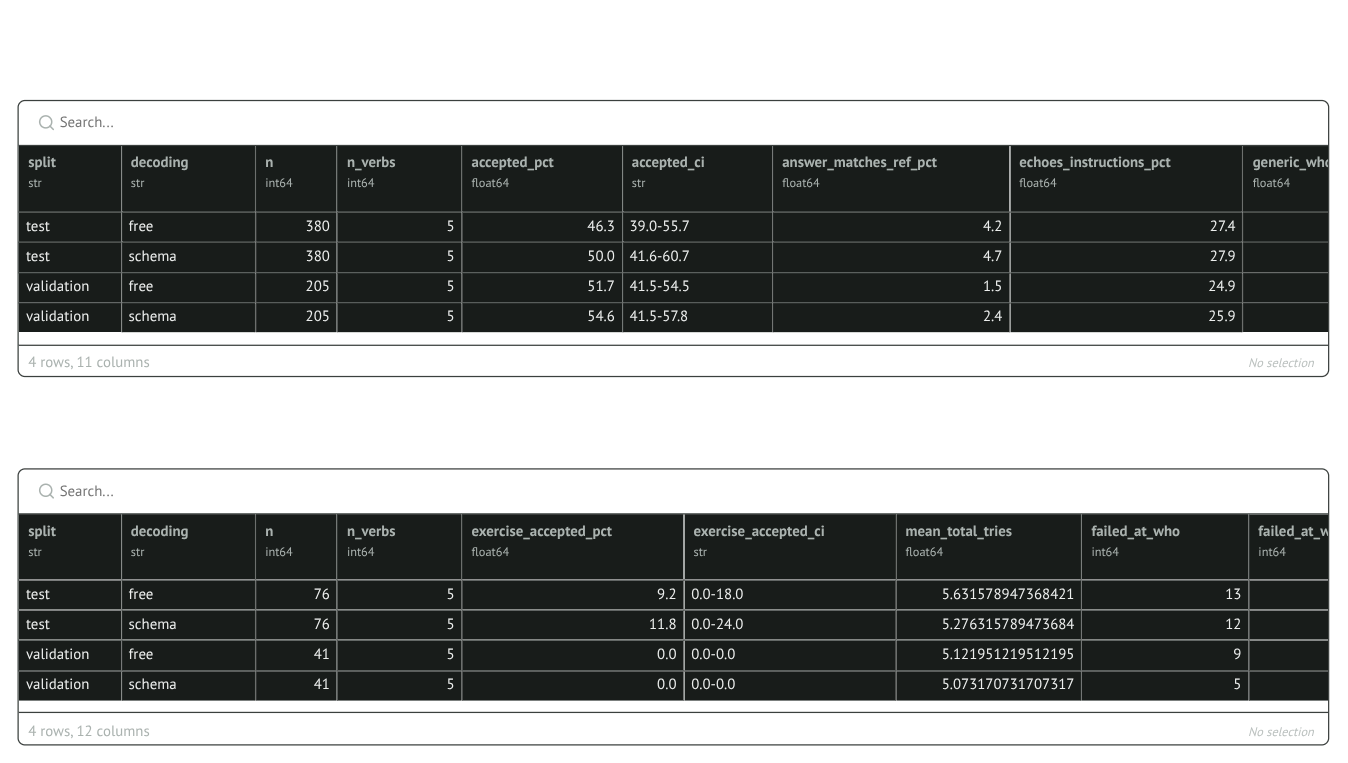

In [ ]:
# ───────────── stage: summary tables (always recomputed from the scored outputs, so they can never go stale) ─────────────
def _bools(df_, cols_):
    for c_ in cols_:
        if c_ in df_:
            df_[c_] = df_[c_].astype(str).str.lower().isin(["true", "1"]) if df_[c_].dtype == object else df_[c_].astype(bool)
    return df_

def _put(df_, what_):
    path_ = wc.table_path(EXP_ID, NOTEBOOK, what_)
    lp_ = WORK_DIR / path_
    lp_.parent.mkdir(parents=True, exist_ok=True)
    df_.to_csv(lp_, index=False)
    wc.hf_upload(lp_, path_, f"{RUN_NAME}: {path_}", HF_TOKEN)
    return path_

_model = "Llama-3.2-1B-Instruct (untuned, bf16)"
FORCED = _bools(pd.concat([v for (_s, _p, _d), v in SCORED.items() if _p == "forced"], ignore_index=True), wc.PART_METRICS) \
    if any(_p == "forced" for (_s, _p, _d) in SCORED) else pd.DataFrame()
CHAIN = _bools(pd.concat([v for (_s, _p, _d), v in SCORED.items() if _p == "chain"], ignore_index=True), wc.CHAIN_METRICS) \
    if any(_p == "chain" for (_s, _p, _d) in SCORED) else pd.DataFrame()
TABLES = {}
if FORCED.empty and CHAIN.empty:
    print("[summary] nothing scored yet: no tables written")
else:
    if not FORCED.empty:
        TABLES["forced-summary"] = wc.summarise(FORCED, ["split", "decoding"], metrics=wc.PART_METRICS)
        TABLES["forced-by-part"] = wc.summarise(FORCED, ["split", "decoding", "part"], metrics=wc.PART_METRICS)
    if not CHAIN.empty:
        _cs = wc.summarise(CHAIN, ["split", "decoding"], metrics=wc.CHAIN_METRICS)
        _extra = CHAIN.groupby(["split", "decoding"]).agg(
            mean_total_tries=("total_tries", "mean"),
            **{f"failed_at_{p}": ("failed_part", lambda s, p=p: int((s == p).sum())) for p in wc.QUESTIONS}).reset_index()
        TABLES["chain-summary"] = _cs.merge(_extra, on=["split", "decoding"])
    _pv = []
    if not FORCED.empty:
        _pv.append(wc.summarise(FORCED[FORCED["split"] == "test"], ["decoding", "verb"], metrics=["accepted"]).assign(protocol="forced"))
    if not CHAIN.empty:
        _pv.append(wc.summarise(CHAIN[CHAIN["split"] == "test"], ["decoding", "verb"], metrics=wc.CHAIN_METRICS).assign(protocol="chain"))
    TABLES["per-verb"] = pd.concat(_pv, ignore_index=True)
    for _what, _df in TABLES.items():
        _df.insert(0, "model", _model)
        print(f"[summary] {_what} -> {_put(_df, _what)}")
    if log_fn:
        for _r in TABLES.get("forced-summary", pd.DataFrame()).to_dict("records"):
            log_fn({f"forced/{_r['split']}/{_r['decoding']}/{m}_pct": _r[f"{m}_pct"] for m in wc.PART_METRICS})
        for _r in TABLES.get("chain-summary", pd.DataFrame()).to_dict("records"):
            log_fn({f"chain/{_r['split']}/{_r['decoding']}/exercise_accepted_pct": _r["exercise_accepted_pct"],
                    f"chain/{_r['split']}/{_r['decoding']}/mean_total_tries": _r["mean_total_tries"]})
    stages.mark_done("summary", {"tables": [wc.table_path(EXP_ID, NOTEBOOK, w) for w in TABLES]})
_show_f = ["split", "decoding", "n", "n_verbs", "accepted_pct", "accepted_ci", "answer_matches_ref_pct", "echoes_instructions_pct",
           "generic_who_pct", "any_bad_distractor_pct", "mean_gen_tokens"]
_show_c = ["split", "decoding", "n", "n_verbs", "exercise_accepted_pct", "exercise_accepted_ci", "mean_total_tries"] + \
          [f"failed_at_{p}" for p in wc.QUESTIONS]
_f, _c = TABLES.get("forced-summary", pd.DataFrame()), TABLES.get("chain-summary", pd.DataFrame())
mo.vstack([mo.md("### Forced: each question on its own (automatic scores; test = 5 verbs)"),
           mo.ui.table(_f[[c for c in _show_f if c in _f]] if not _f.empty else _f, selection=None),
           mo.md("### Chain: whole exercises written the app's way (≤ 3 tries per question)"),
           mo.ui.table(_c[[c for c in _show_c if c in _c]] if not _c.empty else _c, selection=None)])

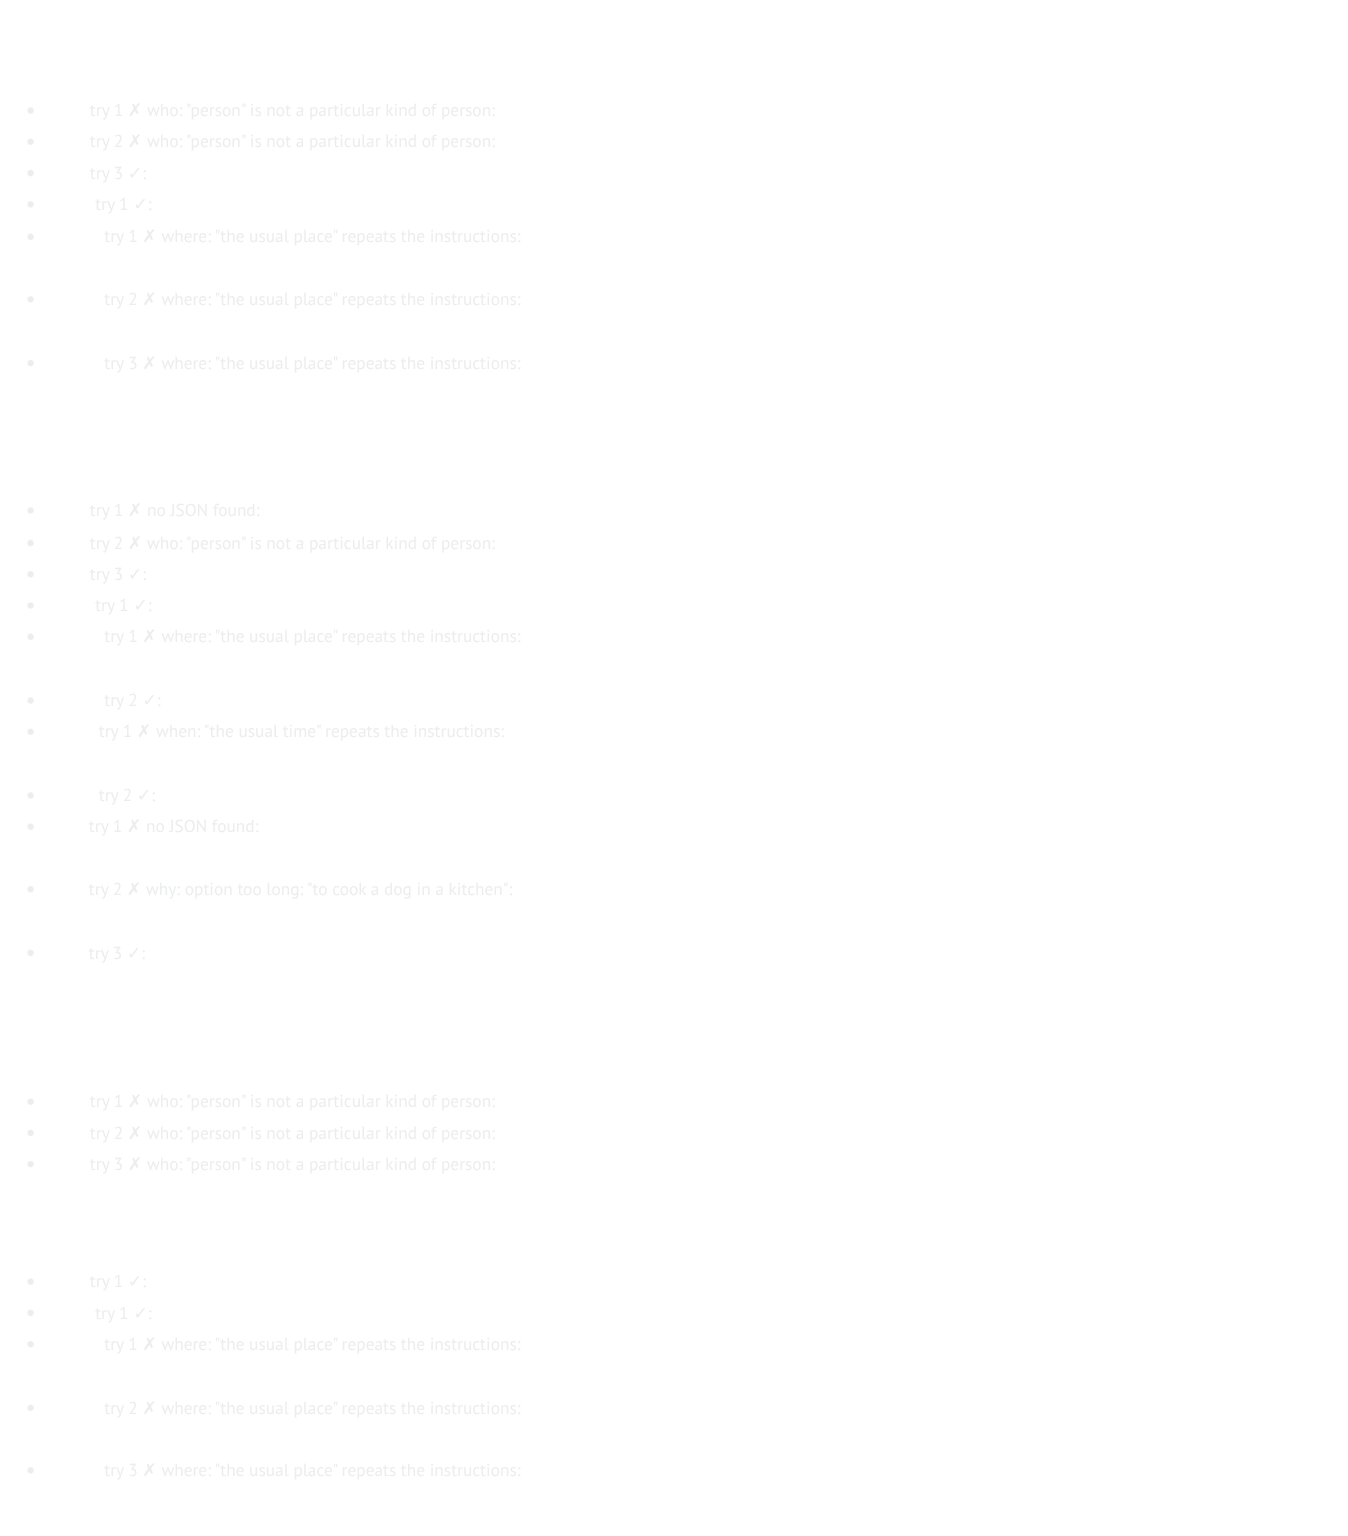

In [ ]:
# Two chained test exercises per decoding, with every try, to read
_blocks = []
for (_s, _p, _d), _att in sorted(ATTEMPTS.items()):
    if _s != "test":
        continue
    for _ex in list(dict.fromkeys(_att["exercise_id"]))[:2]:
        _rows = _att[_att["exercise_id"] == _ex]
        _txt = "\n".join(f"- **{r.part}** try {r.try_} {'✓' if str(r.passed).lower() == 'true' else '✗ ' + str(r.reason)}: `{str(r.output)[:200]}`"
                         for r in _rows.rename(columns={"try": "try_"}).itertuples())
        _blocks.append(mo.md(f"#### {_d} decoding · {_ex}\n\n{_txt}"))
mo.vstack(_blocks) if _blocks else mo.md("_no chained outputs yet_")

In [ ]:
# ───────────── finish: outcome tag, close W&B ─────────────
if wb is not None:
    try:
        import wandb as _wandb
        for _what, _df in TABLES.items():
            wb.log({f"{_what}_table": _wandb.Table(dataframe=_df)})
        wb.tags = tuple(set(wb.tags) | {"outcome:neutral"})  # a baseline is a reference point, not a success/failure
    except Exception as _e:
        print(f"[wandb] final logging skipped: {str(_e)[:80]}")
    wb.finish()
print("done. Next: copy the test rows of tables/b2__2.02__forced-summary.csv and chain-summary.csv into RESEARCH_LOG §6.1, "
      "update the notebook register, and add an Experiment Log entry.")

wandb: uploading artifact run-b2-llama32-1b-instruct-untuned-forced-summary_table; uploading artifact run-b2-llama32-1b-instruct-untuned-forced-by-part_table; uploading artifact run-b2-llama32-1b-instruct-untuned-chain-summary_table; uploading artifact run-b2-llama32-1b-instruct-untuned-per-verb_table; updating run metadata
wandb: uploading artifact run-b2-llama32-1b-instruct-untuned-forced-summary_table; uploading artifact run-b2-llama32-1b-instruct-untuned-forced-by-part_table; uploading artifact run-b2-llama32-1b-instruct-untuned-chain-summary_table; uploading artifact run-b2-llama32-1b-instruct-untuned-per-verb_table
wandb: uploading artifact run-b2-llama32-1b-instruct-untuned-forced-by-part_table; uploading artifact run-b2-llama32-1b-instruct-untuned-chain-summary_table; uploading artifact run-b2-llama32-1b-instruct-untuned-per-verb_table
wandb: uploading history steps 0-3, summary, console lines 55-62
wandb: uploading media/table/per-verb_table_3_38fb0ef06764531091cc.table.json; 

done. Next: copy the test rows of tables/b2__2.02__forced-summary.csv and chain-summary.csv into RESEARCH_LOG §6.1, update the notebook register, and add an Experiment Log entry.
